In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv(next(Path("../data/raw").glob("*.csv")))

target = "sleep_debt_category"
order = ["Optimal Recovery", "Mild Deficit", "Moderate Debt", "Severe Sleep Debt"]
palette = dict(zip(order, ["#4c9f70", "#e0c341", "#e08a3c", "#c0392b"]))
num_cols = [c for c in df.select_dtypes("number").columns if c != "blue_light_filter_active"]
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in (target, "user_id")] + ["blue_light_filter_active"]

# 1.Biểu đồ phân bố biến mục tiêu
--> Phát hiện mất cân bằng (Moderate 52,5%, Severe chỉ 7,6%), từ đó quyết định dùng stratify, class_weight và chọn thước đo như F1 thay vì chỉ accuracy

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x=target, order=order, palette=palette, hue=target, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Phân bố sleep_debt_category")
ax.set_xlabel("")
plt.show()

# 2.Biểu đồ histogram các cột số
-->Phát hiện lệch phải (caffeine, thời gian dùng điện thoại), cột bị cắt khoảng (fatigue chạm 1 và 10, ngủ chạm sàn 3,2 giờ), biến nhiều số 0. Giúp quyết định có cần biến đổi dữ liệu không

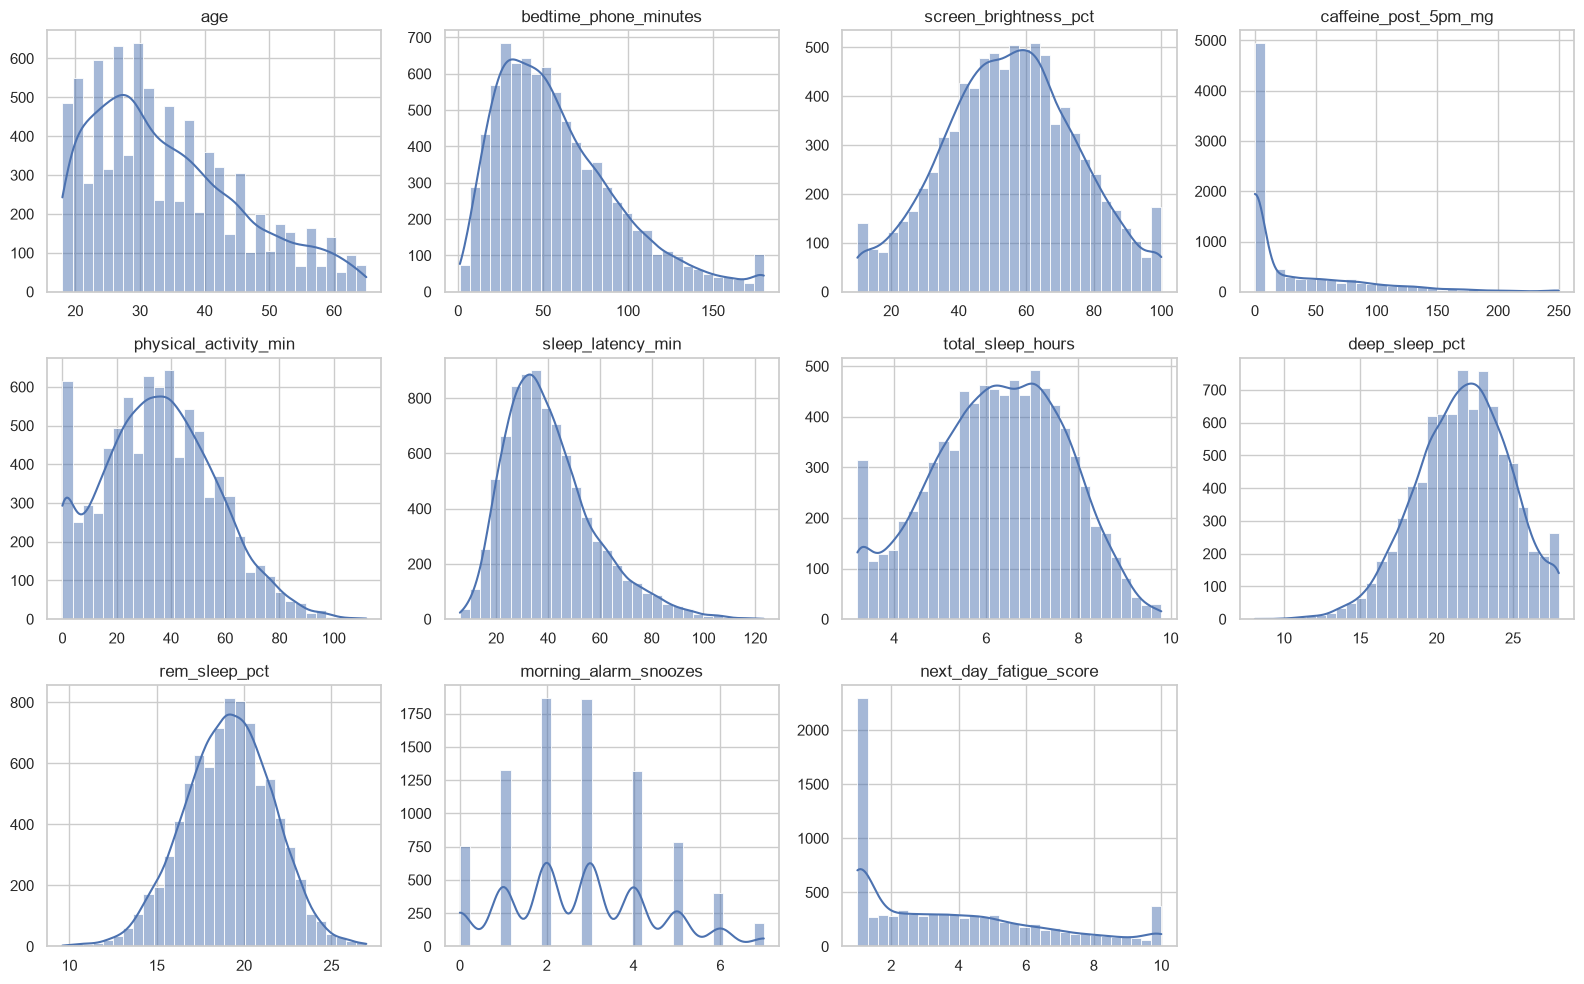

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in list(axes.flat)[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 3.Boxplot từng cột số
Cho biết cột nào có nhiều điểm xa số đông (nhiều nhất là caffeine, 5,7%), xét giá trị đó hợp lý hay là lỗi để quyết định giữ hay loại

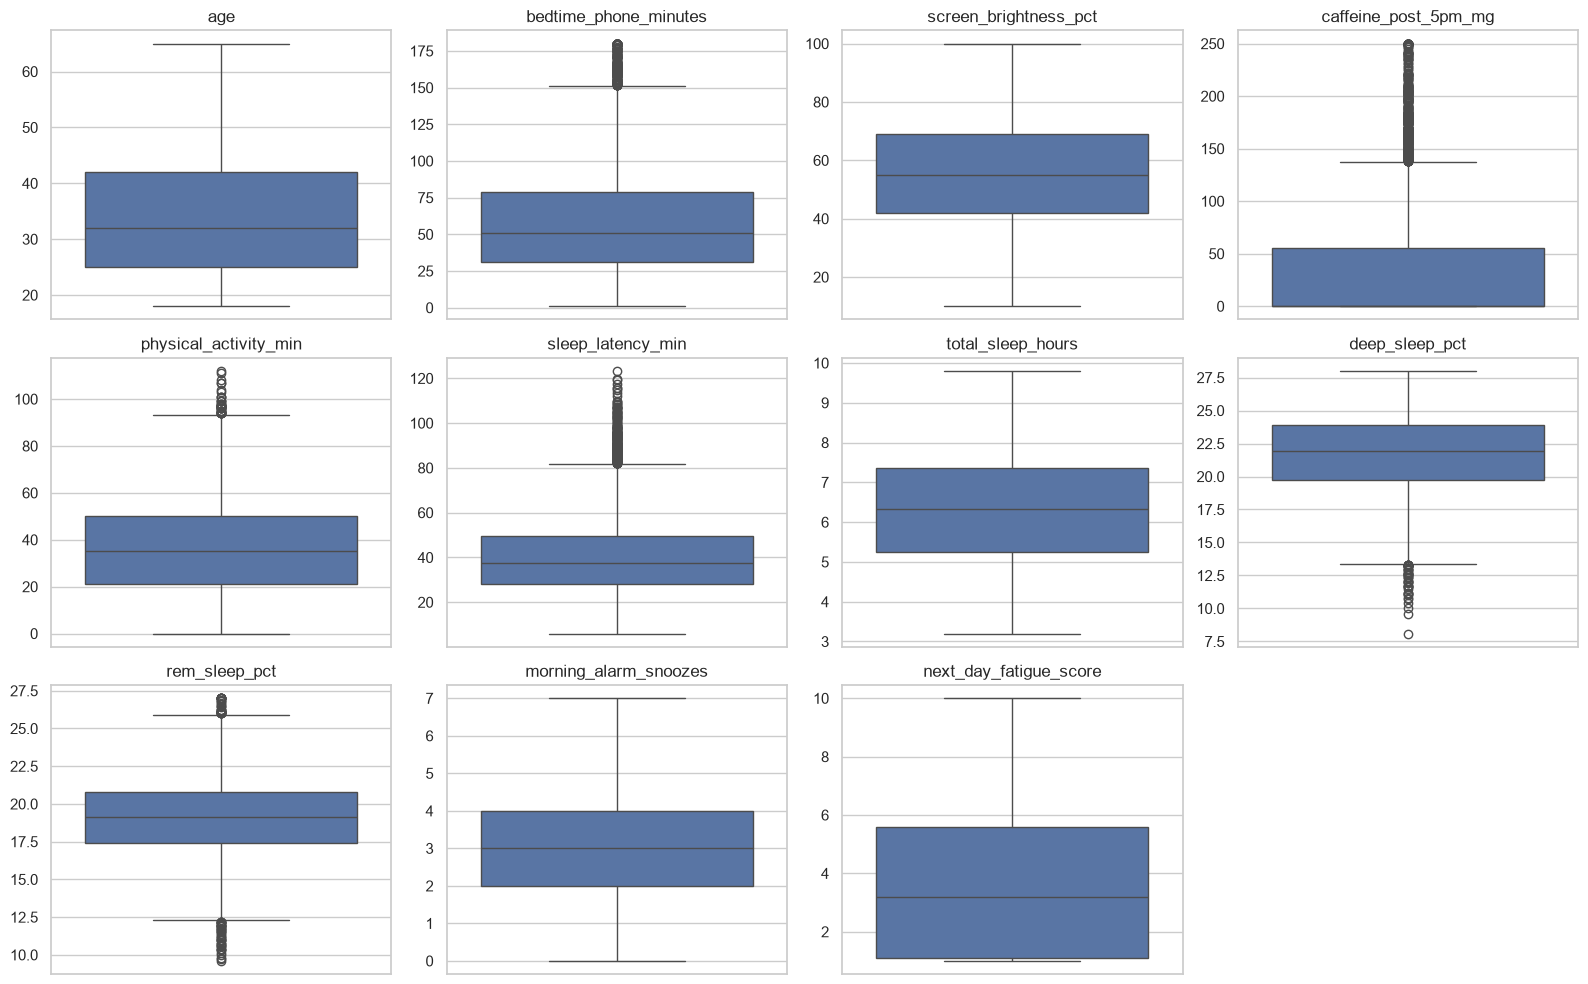

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
for ax in list(axes.flat)[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 4.Heatmap tương quan
Phát hiện cặp biến liên quan mạnh (điện thoại và thời gian khó ngủ 0,86), nhóm biến trùng thông tin (đa cộng tuyến), và biến không liên quan gì (tuổi, độ sáng)

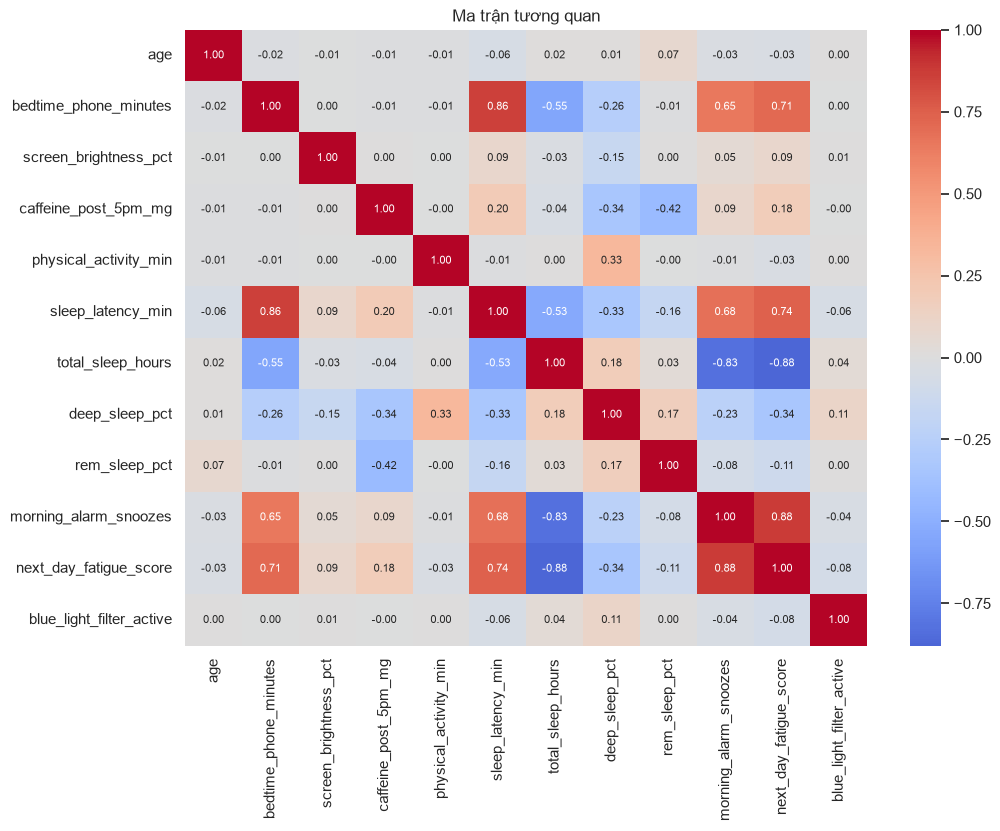

In [7]:
corr = df[num_cols + ["blue_light_filter_active"]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Ma trận tương quan")
plt.show()

# 5.Boxplot theo nhóm mục tiêu (cột số)
Chọn biến đầu vào có giá trị dự đoán (bedtime_phone_minutes), đồng thời phát hiện rò rỉ nhãn (total_sleep_hours) và các cột hệ quả cần loại

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x=target, y=col, order=order, palette=palette,
                hue=target, legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks(range(4), ["Optimal", "Mild", "Moderate", "Severe"])
for ax in list(axes.flat)[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 6.Tỷ lệ nhóm theo cột phân loại (thanh xếp chồng)
Cho biết chronotype và occupation_type có ảnh hưởng rõ, còn gender và blue_light_filter_active gần như không

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, cat_cols):
    ct = pd.crosstab(df[col], df[target], normalize="index")[order]
    ct = ct.loc[ct["Severe Sleep Debt"].sort_values().index]
    ct.plot.barh(stacked=True, color=[palette[o] for o in order], ax=ax, legend=False)
    ax.set_title(col)
    ax.set_ylabel("")
    ax.set_xlim(0, 1)
for ax in list(axes.flat)[len(cat_cols):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

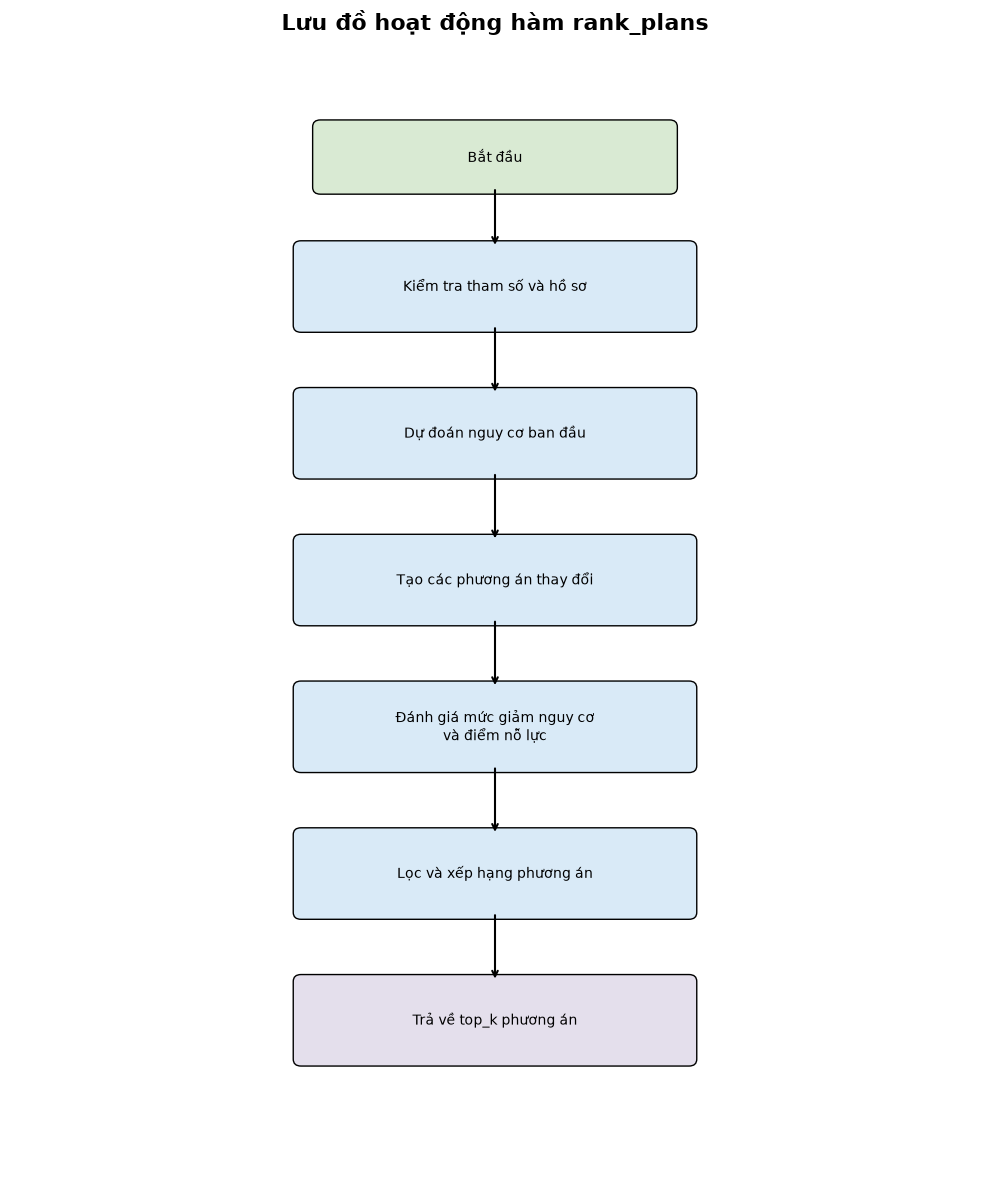

In [5]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

fig, ax = plt.subplots(figsize=(10, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, 13)
ax.axis("off")

ax.set_title(
    "Lưu đồ hoạt động hàm rank_plans",
    fontsize=16,
    fontweight="bold",
    pad=20
)

def box(x, y, w, h, text, kind="process"):
    colors = {
        "start": "#D9EAD3",
        "process": "#D9EAF7",
        "decision": "#FFF2CC",
        "end": "#E4DFEC"
    }

    if kind == "decision":
        shape = Polygon(
            [(x+w/2, y+h), (x+w, y+h/2),
             (x+w/2, y), (x, y+h/2)],
            closed=True,
            facecolor=colors[kind],
            edgecolor="black"
        )
    else:
        shape = FancyBboxPatch(
            (x, y), w, h,
            boxstyle="round,pad=0.08",
            facecolor=colors[kind],
            edgecolor="black"
        )

    ax.add_patch(shape)
    ax.text(x+w/2, y+h/2, text,
            ha="center", va="center",
            fontsize=10, wrap=True)

def arrow(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

# Các bước chính
box(3.2, 11.5, 3.6, 0.7,
    "Bắt đầu", "start")

box(3.0, 9.9, 4.0, 0.9,
    "Kiểm tra tham số và hồ sơ")

box(3.0, 8.2, 4.0, 0.9,
    "Dự đoán nguy cơ ban đầu")

box(3.0, 6.5, 4.0, 0.9,
    "Tạo các phương án thay đổi")

box(3.0, 4.8, 4.0, 0.9,
    "Đánh giá mức giảm nguy cơ\nvà điểm nỗ lực")

box(3.0, 3.1, 4.0, 0.9,
    "Lọc và xếp hạng phương án")

box(3.0, 1.4, 4.0, 0.9,
    "Trả về top_k phương án", "end")

# Các mũi tên
arrow(5, 11.5, 5, 10.8)
arrow(5, 9.9, 5, 9.1)
arrow(5, 8.2, 5, 7.4)
arrow(5, 6.5, 5, 5.7)
arrow(5, 4.8, 5, 4.0)
arrow(5, 3.1, 5, 2.3)

plt.tight_layout()
plt.savefig("luu_do_rank_plans_don_gian.png",
            dpi=300, bbox_inches="tight")
plt.show()
